# 5. Stability and Stiff Equations

Accuracy is not the only concern. A method can also be **unstable**: for a step that is too large, errors are amplified at every step and the numerical solution blows up, even though the true solution decays. This section shows how to predict when that happens, introduces **implicit** methods that avoid it, and explains **stiff** equations, where stability rather than accuracy decides the step size.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True
np.set_printoptions(precision=6, suppress=True)

def euler(f, x0, y0, h, n):
    x, y = np.zeros(n + 1), np.zeros(n + 1)
    x[0], y[0] = x0, y0
    for i in range(n):
        y[i + 1] = y[i] + h * f(x[i], y[i])
        x[i + 1] = x[i] + h
    return x, y

def rk4(f, x0, y0, h, n):
    x, y = np.zeros(n + 1), np.zeros(n + 1)
    x[0], y[0] = x0, y0
    for i in range(n):
        k1 = f(x[i], y[i])
        k2 = f(x[i] + h / 2, y[i] + h / 2 * k1)
        k3 = f(x[i] + h / 2, y[i] + h / 2 * k2)
        k4 = f(x[i] + h, y[i] + h * k3)
        y[i + 1] = y[i] + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        x[i + 1] = x[i] + h
    return x, y

## 5.1 The test equation

Stability is studied with the linear **test equation**

$$y' = \lambda y, \qquad y(0) = 1, \qquad \text{exact solution } y = e^{\lambda x}.$$

When $\lambda < 0$ (or, for complex $\lambda$, when $\operatorname{Re}\lambda < 0$) the exact solution decays to $0$. A good method should reproduce that.

Why this equation? Near any solution, a small perturbation $\delta$ of a general equation $y' = f(x, y)$ evolves approximately like $\delta' = \frac{\partial f}{\partial y}\,\delta$. So $\lambda$ plays the role of $\partial f/\partial y$, and what a method does to the test equation tells us what it does to errors in general.

Applying a one-step method to the test equation always gives

$$y_{n+1} = R(z)\,y_n, \qquad z = h\lambda,$$

so $y_n = R(z)^n$. $R$ is the method's **amplification factor** (or stability function).

| Method | $R(z)$ |
|---|---|
| Euler | $1 + z$ |
| Any two-stage order 2 method (Heun, midpoint, Ralston) | $1 + z + \frac{z^2}{2}$ |
| RK4 | $1 + z + \frac{z^2}{2} + \frac{z^3}{6} + \frac{z^4}{24}$ |
| Backward Euler (Section 5.4) | $\dfrac{1}{1 - z}$ |
| Trapezoidal (Section 5.4) | $\dfrac{1 + z/2}{1 - z/2}$ |

*Example (Heun):* $k_1 = \lambda y_n$, $k_2 = \lambda(y_n + h\lambda y_n)$, so $y_{n+1} = y_n + \tfrac{h}{2}(2\lambda y_n + h\lambda^2 y_n) = (1 + z + \tfrac{z^2}{2})\,y_n$.

For explicit Runge–Kutta methods with $p = s \le 4$, $R(z)$ is the Taylor polynomial of $e^{z}$ up to $z^p$. That makes sense: $e^{z}$ is the exact amplification over one step.

The numerical solution decays only if $|R(z)| < 1$. The set

$$S = \{ z \in \mathbb{C} : |R(z)| \le 1 \}$$

is the method's **region of absolute stability**. A step size $h$ is stable for the equation if $z = h\lambda$ lies in $S$.

## 5.2 Euler's stability limit

For Euler with real $\lambda < 0$: $|1 + h\lambda| < 1$ requires

$$\boxed{h < \frac{2}{|\lambda|}} \quad\text{(Euler's stability limit).}$$

With $\lambda = -20$ the limit is $h < 0.1$:

| $h$ | $R = 1 - 20h$ | behaviour |
|---|---|---|
| 0.02 | 0.6 | smooth decay, like the exact solution |
| 0.08 | −0.6 | decays, but flips sign every step |
| 0.12 | −1.4 | oscillates and grows without bound |

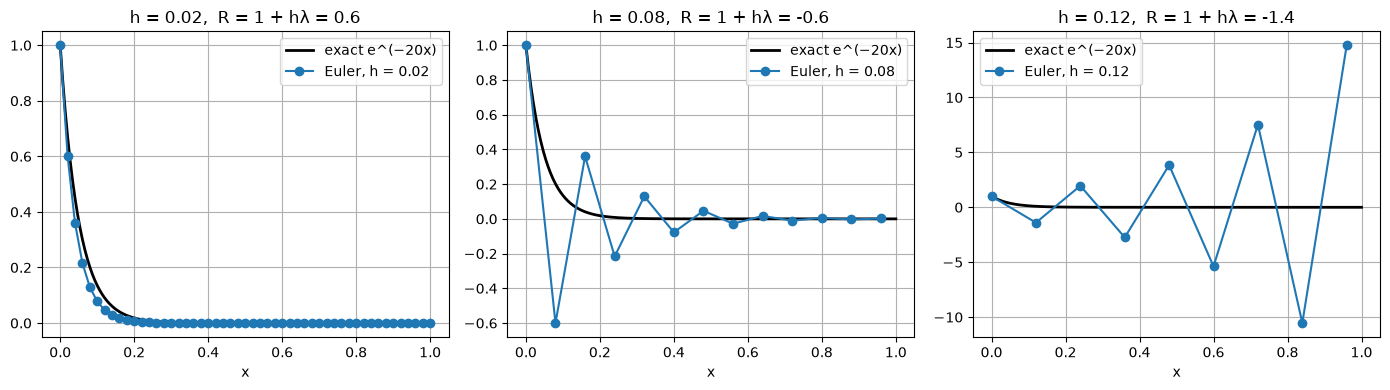

In [2]:
lam = -20.0
decay = lambda x, y: lam * y
xf = np.linspace(0, 1, 300)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, h in zip(axes, [0.02, 0.08, 0.12]):
    n = round(1 / h)
    x, y = euler(decay, 0, 1, h, n)
    ax.plot(xf, np.exp(lam * xf), "k", lw=2, label="exact e^(−20x)")
    ax.plot(x, y, "o-", label=f"Euler, h = {h}")
    ax.set_title(f"h = {h},  R = 1 + hλ = {1 + lam*h:.1f}")
    ax.set_xlabel("x"); ax.legend()
plt.tight_layout()

Note that $h = 0.12$ is not an unusually large step: over $[0, 1]$ it is only about 8 steps. The instability is not a matter of accuracy. **Any** error, even rounding at the level of $10^{-16}$, is multiplied by $|R| = 1.4$ at every step.

## 5.3 Stability regions

Plotting $S$ in the complex $z$-plane shows at a glance which step sizes are safe for which $\lambda$. Complex $\lambda$ matter for oscillating solutions and for systems of equations ([Section 8](08-systems-and-higher-order.ipynb)).

Euler      : stable for real λ < 0 when h|λ| ≤ 2.0000
RK2 (Heun) : stable for real λ < 0 when h|λ| ≤ 2.0000
RK4        : stable for real λ < 0 when h|λ| ≤ 2.7853


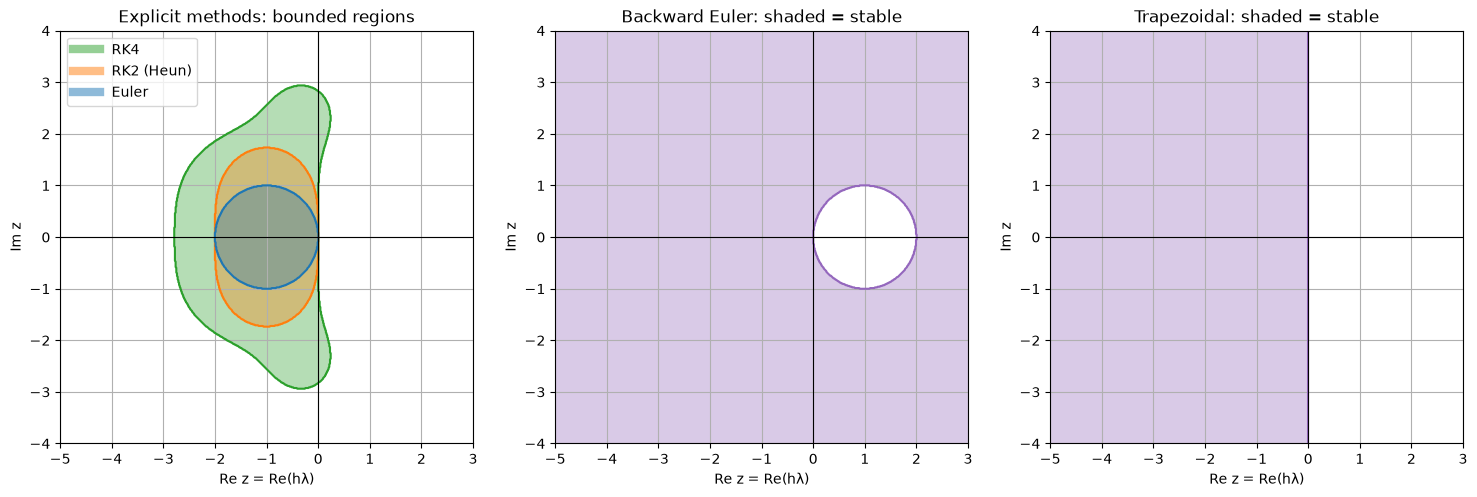

In [3]:
R = {
    "Euler": lambda z: 1 + z,
    "RK2 (Heun)": lambda z: 1 + z + z**2 / 2,
    "RK4": lambda z: 1 + z + z**2 / 2 + z**3 / 6 + z**4 / 24,
    "Backward Euler": lambda z: 1 / (1 - z),
    "Trapezoidal": lambda z: (1 + z / 2) / (1 - z / 2),
}

re, im = np.meshgrid(np.linspace(-5, 3, 600), np.linspace(-4, 4, 600))
Z = re + 1j * im

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for name, color in [("RK4", "C2"), ("RK2 (Heun)", "C1"), ("Euler", "C0")]:
    stable = (np.abs(R[name](Z)) <= 1).astype(float)
    axes[0].contourf(re, im, stable, levels=[0.5, 1.5], colors=[color], alpha=0.35)
    axes[0].contour(re, im, stable, levels=[0.5], colors=[color])
    axes[0].plot([], [], color=color, lw=6, alpha=0.5, label=name)
axes[0].set_title("Explicit methods: bounded regions")
for ax, name in zip(axes[1:], ["Backward Euler", "Trapezoidal"]):
    stable = (np.abs(R[name](Z)) <= 1 + 1e-12).astype(float)
    ax.contourf(re, im, stable, levels=[0.5, 1.5], colors=["C4"], alpha=0.35)
    ax.contour(re, im, stable, levels=[0.5], colors=["C4"])
    ax.set_title(f"{name}: shaded = stable")
for ax in axes:
    ax.axhline(0, color="k", lw=0.8); ax.axvline(0, color="k", lw=0.8)
    ax.set_xlabel("Re z = Re(hλ)"); ax.set_ylabel("Im z")
    ax.set_aspect("equal")
axes[0].legend(loc="upper left")
plt.tight_layout()

# Stability interval on the negative real axis: largest a with |R(-a)| <= 1
def real_limit(Rf):
    a = np.linspace(1e-6, 10, 200001)
    ok = np.abs(Rf(-a)) <= 1
    return a[np.argmin(ok)] if not ok.all() else np.inf

for name in ["Euler", "RK2 (Heun)", "RK4"]:
    print(f"{name:11s}: stable for real λ < 0 when h|λ| ≤ {real_limit(R[name]):.4f}")

* The explicit methods have **bounded** stability regions. Higher order buys a somewhat larger region (RK4 reaches $h|\lambda| \le 2.785$ on the real axis), but it is always bounded: $R$ is a polynomial, so $|R(z)| \to \infty$ as $|z| \to \infty$. **No explicit Runge–Kutta method can be stable for every step size.**
* The implicit methods' regions contain the **whole left half-plane**. Their step size is never limited by stability on decaying problems.

### Oscillating solutions

For purely imaginary $\lambda = i\omega$ the exact solution $e^{i\omega x}$ oscillates with **constant** amplitude: $|e^{z}| = 1$. On the imaginary axis,

* Euler: $|1 + iy| = \sqrt{1 + y^2} > 1$ for **every** step: the amplitude always grows.
* RK2: $|1 + iy - y^2/2|^2 = 1 + y^4/4 > 1$: also grows, but much more slowly.
* RK4: $|R(iy)|^2 = 1 - \frac{y^6}{72} + \frac{y^8}{576} \le 1$ for $|y| \le 2\sqrt2$: slight damping.

Euler: |y| at x = 50 is 12.032156   (exact 1)
RK4  : |y| at x = 50 is 0.999997   (exact 1)


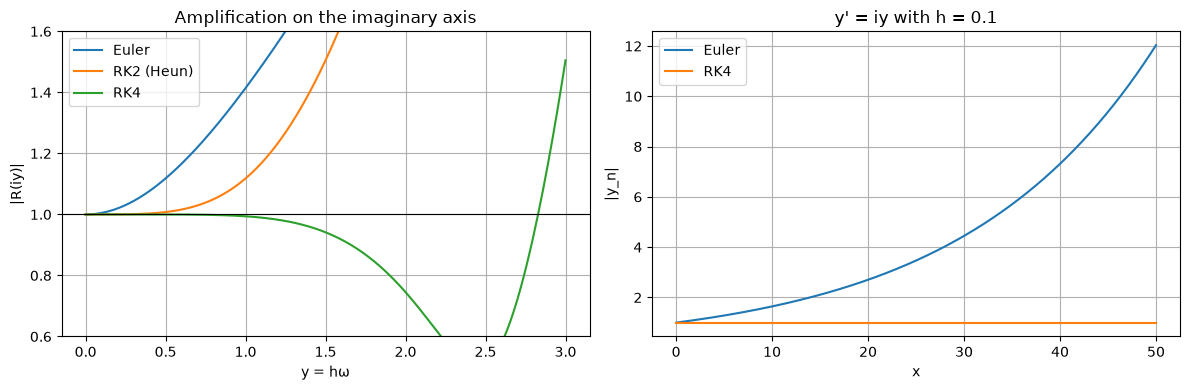

In [4]:
osc = lambda x, y: 1j * y          # y' = i y, exact |y| = 1 for all x
h, n = 0.1, 500                    # 50 units of x, about 8 periods

def euler_c(f, y0, h, n):
    y = np.zeros(n + 1, dtype=complex); y[0] = y0
    for i in range(n):
        y[i + 1] = y[i] + h * f(i * h, y[i])
    return y

def rk4_c(f, y0, h, n):
    y = np.zeros(n + 1, dtype=complex); y[0] = y0
    for i in range(n):
        x = i * h
        k1 = f(x, y[i]); k2 = f(x + h/2, y[i] + h/2 * k1)
        k3 = f(x + h/2, y[i] + h/2 * k2); k4 = f(x + h, y[i] + h * k3)
        y[i + 1] = y[i] + h / 6 * (k1 + 2*k2 + 2*k3 + k4)
    return y

ys = {"Euler": euler_c(osc, 1, h, n), "RK4": rk4_c(osc, 1, h, n)}
yr = np.linspace(0, 3, 300)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in ["Euler", "RK2 (Heun)", "RK4"]:
    axes[0].plot(yr, np.abs(R[name](1j * yr)), label=name)
axes[0].axhline(1, color="k", lw=0.8)
axes[0].set_ylim(0.6, 1.6); axes[0].set_xlabel("y = hω"); axes[0].set_ylabel("|R(iy)|")
axes[0].set_title("Amplification on the imaginary axis"); axes[0].legend()
xs = h * np.arange(n + 1)
for name, y in ys.items():
    axes[1].plot(xs, np.abs(y), label=name)
    print(f"{name:5s}: |y| at x = 50 is {abs(y[-1]):.6f}   (exact 1)")
axes[1].set_xlabel("x"); axes[1].set_ylabel("|y_n|"); axes[1].set_title("y' = iy with h = 0.1")
axes[1].legend()
plt.tight_layout()

Euler's amplitude grows by the factor $(1 + h^2)^{1/2}$ every step, about 12 times over 500 steps. RK4 loses only a tiny fraction of the amplitude. This matters for simulating anything that oscillates (pendulums, orbits, circuits); see [Section 8](08-systems-and-higher-order.ipynb).

## 5.4 Implicit methods

**Backward (implicit) Euler** uses the slope at the *end* of the step:

$$y_{n+1} = y_n + h\,f(x_{n+1}, y_{n+1}).$$

For the test equation this gives $y_{n+1} = y_n + z\,y_{n+1}$, so

$$y_{n+1} = \frac{y_n}{1 - z}, \qquad |R(z)| = \frac{1}{|1 - z|} \le 1 \text{ whenever } \operatorname{Re} z \le 0.$$

The **trapezoidal method** averages the slopes at both ends, without Heun's predictor:

$$y_{n+1} = y_n + \frac{h}{2}\Big[f(x_n, y_n) + f(x_{n+1}, y_{n+1})\Big], \qquad R(z) = \frac{1 + z/2}{1 - z/2}.$$

It has order 2; backward Euler has order 1.

**The price.** For a general $f$, each step requires **solving** an equation for $y_{n+1}$. For backward Euler the equation is

$$g(Y) = Y - y_n - h\,f(x_{n+1}, Y) = 0,$$

which is solved with Newton's method, $Y \leftarrow Y - g(Y)/g'(Y)$, where $g'(Y) = 1 - h\,\partial f/\partial y$. The code below estimates $\partial f/\partial y$ with a finite difference, so it works for any $f$.

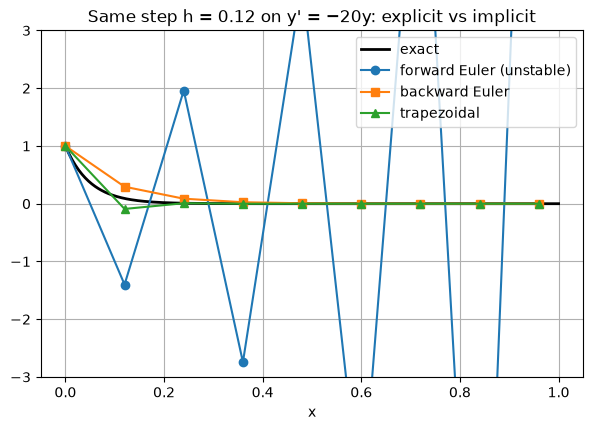

In [5]:
def dfdy(f, x, y, eps=1e-7):
    return (f(x, y + eps) - f(x, y - eps)) / (2 * eps)

def newton(g, dg, Y, tol=1e-12, maxiter=50):
    for _ in range(maxiter):
        step = g(Y) / dg(Y)
        Y -= step
        if abs(step) < tol * (1 + abs(Y)):
            break
    return Y

def backward_euler(f, x0, y0, h, n):
    x, y = x0 + h * np.arange(n + 1), np.zeros(n + 1)
    y[0] = y0
    for i in range(n):
        xn1 = x[i + 1]
        g = lambda Y: Y - y[i] - h * f(xn1, Y)
        dg = lambda Y: 1 - h * dfdy(f, xn1, Y)
        y[i + 1] = newton(g, dg, y[i])
    return x, y

def trapezoidal(f, x0, y0, h, n):
    x, y = x0 + h * np.arange(n + 1), np.zeros(n + 1)
    y[0] = y0
    for i in range(n):
        xn1, fn = x[i + 1], f(x[i], y[i])
        g = lambda Y: Y - y[i] - h / 2 * (fn + f(xn1, Y))
        dg = lambda Y: 1 - h / 2 * dfdy(f, xn1, Y)
        y[i + 1] = newton(g, dg, y[i])
    return x, y

# Check on y' = -20 y with the unstable Euler step h = 0.12
h = 0.12
x, y_fwd = euler(decay, 0, 1, h, round(1 / h))
_, y_bwd = backward_euler(decay, 0, 1, h, round(1 / h))
_, y_trap = trapezoidal(decay, 0, 1, h, round(1 / h))
plt.plot(xf, np.exp(lam * xf), "k", lw=2, label="exact")
plt.plot(x, y_fwd, "o-", label="forward Euler (unstable)")
plt.plot(x, y_bwd, "s-", label="backward Euler")
plt.plot(x, y_trap, "^-", label="trapezoidal")
plt.ylim(-3, 3)
plt.title(f"Same step h = {h} on y' = −20y: explicit vs implicit")
plt.xlabel("x"); plt.legend();

### A-stability and L-stability

* A method is **A-stable** if its stability region contains the whole left half-plane $\operatorname{Re} z \le 0$. Backward Euler and trapezoidal are both A-stable.
* Dahlquist's **second barrier**: no explicit Runge–Kutta or explicit multistep method is A-stable, and an A-stable linear multistep method has order at most 2 (the trapezoidal rule is the most accurate one).

A-stability says errors do not grow. For very fast decay we also want them to *disappear quickly*. As $z \to -\infty$:

* backward Euler: $R(z) = \frac{1}{1 - z} \to 0$: fast components are wiped out in one step;
* trapezoidal: $R(z) = \frac{1 + z/2}{1 - z/2} \to -1$: fast components barely decay and flip sign every step.

A method with $R(z) \to 0$ as $z \to -\infty$ is called **L-stable**. Backward Euler is L-stable; the trapezoidal method is not. The plot above already shows the trapezoidal solution flipping sign ($z = -2.4$ gives $R = -0.09$); the next section shows a case where it matters.

## 5.5 Stiff equations

An equation is called **stiff** when stability, not accuracy, forces explicit methods to take tiny steps. This happens when the solution has a very fast-decaying part alongside a slow part. Example:

$$y' = -50\,(y - \cos x), \qquad y(0) = 0.$$

The solution is pulled very quickly towards the slowly varying curve $y \approx \cos x$. It is linear, and solving it with an integrating factor gives

$$y = \frac{2500\cos x + 50\sin x}{2501} - \frac{2500}{2501}\,e^{-50x}.$$

* The transient $e^{-50x}$ is gone after $x \approx 0.1$. After that the solution is smooth and looks like $\cos x$, so accuracy alone would allow steps of size $0.1$ or more.
* But $\partial f / \partial y = -50$, so the explicit stability limits are $h < 2/50 = 0.04$ (Euler) and $h < 2.785/50 \approx 0.056$ (RK4), **for the whole interval**, long after the transient has disappeared.

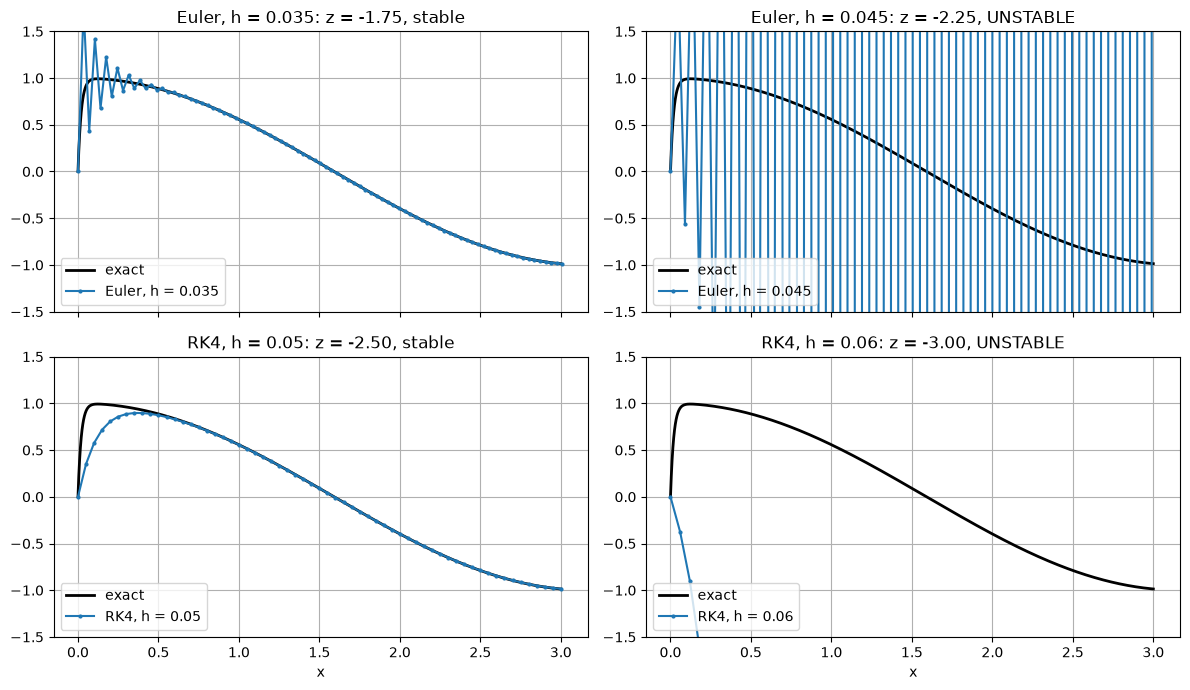

In [6]:
stiff = lambda x, y: -50 * (y - np.cos(x))
stiff_exact = lambda x: (2500 * np.cos(x) + 50 * np.sin(x)) / 2501 - 2500 / 2501 * np.exp(-50 * x)

X = 3.0
xf = np.linspace(0, X, 600)
cases = [("Euler", euler, 0.035), ("Euler", euler, 0.045), ("RK4", rk4, 0.05), ("RK4", rk4, 0.06)]
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, (name, method, h) in zip(axes.flat, cases):
    x, y = method(stiff, 0, 0, h, round(X / h))
    z = -50 * h
    ax.plot(xf, stiff_exact(xf), "k", lw=2, label="exact")
    ax.plot(x, y, ".-", ms=4, label=f"{name}, h = {h}")
    ax.set_ylim(-1.5, 1.5)
    stable = abs(R["Euler" if name == "Euler" else "RK4"](z)) <= 1
    ax.set_title(f"{name}, h = {h}: z = {z:.2f}, {'stable' if stable else 'UNSTABLE'}")
    ax.legend(loc="lower left")
for ax in axes[1]:
    ax.set_xlabel("x")
plt.tight_layout()

Just above the stability limit, both explicit methods blow up, even though the solution they are approximating is as smooth as $\cos x$.

**Implicit methods** take steps chosen for accuracy alone. With $h = 0.5$, more than ten times the explicit limit:

         method      h  steps  max error for x ≥ 1
          Euler  0.035    286             4.31e-04
            RK4  0.050    200             1.15e-03
 Backward Euler  0.100    100             9.98e-04
 Backward Euler  0.500     20             4.94e-03
    Trapezoidal  0.100    100             1.95e-04
    Trapezoidal  0.500     20             7.25e-01


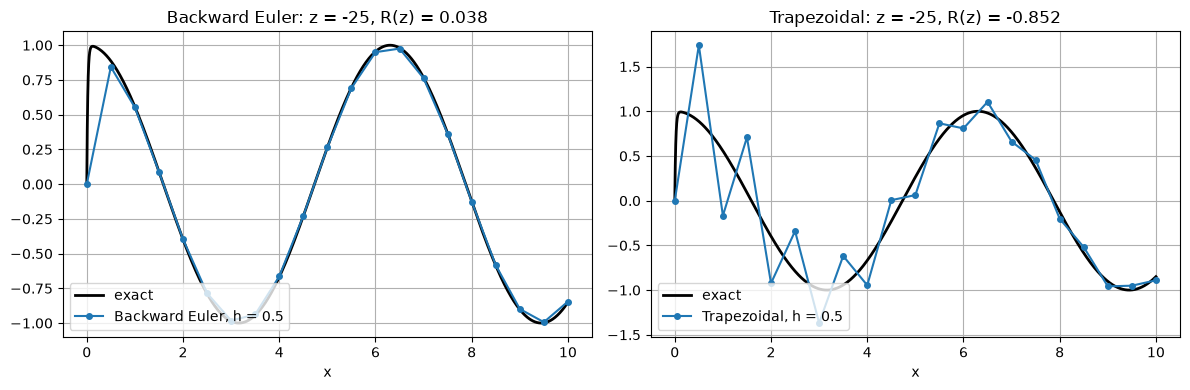

In [7]:
h = 0.5
X = 10.0
xf = np.linspace(0, X, 1000)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, method) in zip(axes, [("Backward Euler", backward_euler), ("Trapezoidal", trapezoidal)]):
    x, y = method(stiff, 0, 0, h, round(X / h))
    ax.plot(xf, stiff_exact(xf), "k", lw=2, label="exact")
    ax.plot(x, y, "o-", ms=4, label=f"{name}, h = {h}")
    ax.set_title(f"{name}: z = {-50*h:.0f}, R(z) = {R[name](-50*h):.3f}")
    ax.set_xlabel("x"); ax.legend(loc="lower left")
plt.tight_layout()

print(f"{'method':>15} {'h':>6} {'steps':>6} {'max error for x ≥ 1':>20}")
for name, method, h in [("Euler", euler, 0.035), ("RK4", rk4, 0.05),
                        ("Backward Euler", backward_euler, 0.1), ("Backward Euler", backward_euler, 0.5),
                        ("Trapezoidal", trapezoidal, 0.1), ("Trapezoidal", trapezoidal, 0.5)]:
    n = round(X / h)
    x, y = method(stiff, 0, 0, h, n)
    mask = x >= 1
    print(f"{name:>15} {h:6.3f} {n:6d} {np.max(np.abs(y[mask] - stiff_exact(x[mask]))):20.2e}")

* **Backward Euler** (left) is stable with $h = 0.5$ and follows the slow solution, with the modest accuracy expected of an order 1 method at that step size. Its $R(-25) = 0.04$ wipes out the transient in one step.
* **Trapezoidal** (right) is also stable, but $R(-25) \approx -0.85$: the transient is not damped quickly, and the solution zig-zags around the true curve for many steps before settling. This is the practical meaning of *not L-stable*.
* In the table, backward Euler and the trapezoidal rule with $h = 0.1$ match or beat the accuracy of the explicit methods with half the steps or fewer, and RK4 needs four evaluations of $f$ per step. Backward Euler stays accurate to about $5 \times 10^{-3}$ even with $h = 0.5$, while the trapezoidal rule at $h = 0.5$ is still dominated by its slowly decaying zig-zag. On stiff problems, the extra cost of solving an equation at every step is more than repaid by the larger steps.

Stiffness is common in practice: chemical reactions with very different rates, electrical circuits, heat conduction after discretising in space, and control systems. Professional stiff solvers use implicit methods such as BDF (backward differentiation formulas), Radau or Rosenbrock methods, for example `solve_ivp(method="BDF")` or `"Radau"` in SciPy, `ode15s` in MATLAB, and `Rodas5` or `FBDF` in Julia's DifferentialEquations.jl.

## 5.6 Summary

* On the test equation $y' = \lambda y$ a method gives $y_{n+1} = R(h\lambda)\,y_n$; it is stable when $|R(h\lambda)| \le 1$.
* Explicit methods have bounded stability regions, so their step size is limited by $|\lambda|$: $h < 2/|\lambda|$ for Euler.
* Implicit methods can be A-stable (no stability limit on decaying problems). L-stable methods also damp fast components quickly.
* A problem is **stiff** when the stability limit of explicit methods is much smaller than the step size accuracy would need. Use an implicit method.

## Exercises

1. What is the largest stable step for Heun's method on $y' = -20y$?
2. Show that backward Euler is A-stable: $|1/(1 - z)| \le 1$ whenever $\operatorname{Re} z \le 0$.
3. Show that the trapezoidal rule's $R(z)$ satisfies $|R(z)| = 1$ on the imaginary axis. What does that mean for $y' = i\omega y$?
4. For $y' = -50(y - \cos x)$, what is the largest stable step for RK4? For backward Euler?

**Answers**

1. $R(z) = 1 + z + z^2/2$ is real for real $z$, and $|R| \le 1$ for $-2 \le z \le 0$. So $20h \le 2$, $h \le 0.1$, the same as Euler.
2. $|1/(1 - z)| \le 1 \iff |1 - z| \ge 1$. If $z = a + ib$ with $a \le 0$, then $|1 - z|^2 = (1 - a)^2 + b^2 \ge 1$.
3. For $z = iy$, the numerator $1 + iy/2$ and denominator $1 - iy/2$ are complex conjugates, so they have equal size. The trapezoidal rule keeps the amplitude of a pure oscillation **exactly** constant, for every step size.
4. $h \le 2.785/50 \approx 0.0557$ for RK4. Backward Euler has no limit.

In [8]:
print(f"1.  Heun limit for λ = −20:   h ≤ {real_limit(R['RK2 (Heun)']) / 20:.4f}")
yy = np.linspace(-10, 10, 5)
print(f"3.  |R(iy)| for the trapezoidal rule at y = {yy}: {np.abs(R['Trapezoidal'](1j * yy))}")
print(f"4.  RK4 limit for λ = −50:    h ≤ {real_limit(R['RK4']) / 50:.4f}")

1.  Heun limit for λ = −20:   h ≤ 0.1000
3.  |R(iy)| for the trapezoidal rule at y = [-10.  -5.   0.   5.  10.]: [1. 1. 1. 1. 1.]
4.  RK4 limit for λ = −50:    h ≤ 0.0557
